# Email Spam Detection using KNN and SVM

**Objective:** Classify emails as spam or not spam using K-Nearest Neighbors (KNN) and Support Vector Machine (SVM), then compare their performance.

**Dataset:** `emails.csv` (place it in the same folder as this notebook). The target column is `Prediction`.

## 1. Install required libraries (if needed)
Skip this cell if the libraries are already installed in your environment.

In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

## 3. Load and inspect the dataset

In [ ]:
df = pd.read_csv("emails.csv")
print("First five rows:")
display(df.head())
print("\nDataset shape:", df.shape)

First five rows:


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0



Dataset shape: (5172, 3002)


## 4. Check and clean the dataset

In [4]:
print("Column names:")
print(df.columns)

print("\nTotal missing values:", df.isnull().sum().sum())

df = df.drop_duplicates().dropna().copy()
target = "Prediction"

print("\nEmail class distribution:")
print(df[target].value_counts())

Column names:
Index(['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='str', length=3002)

Total missing values: 0

Email class distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


## 5. Select features and target

The email identifier is excluded from the features, and `Prediction` is used as the target label.

In [5]:
X = df.iloc[:, 1:-1]
y = df["Prediction"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5172, 3000)
Target shape: (5172,)


## 6. Split the dataset and scale features

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Feature scaling completed.")

Training data: (4137, 3000)
Testing data: (1035, 3000)
Feature scaling completed.


## 7. Train the KNN classifier

In [7]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_predictions = knn.predict(X_test_scaled)
print("KNN model trained successfully.")

KNN model trained successfully.


## 8. Train the SVM classifier

In [8]:
svm = SVC(kernel="linear")
svm.fit(X_train_scaled, y_train)
svm_predictions = svm.predict(X_test_scaled)
print("SVM model trained successfully.")

SVM model trained successfully.


## 9. Evaluate model performance

Accuracy measures overall correctness. Precision, recall, and F1 score are calculated for the positive class (spam, label `1`).

In [9]:
def evaluate_model(name, actual, predicted):
    print("\n" + name)
    print("-" * 35)
    print("Accuracy:", round(accuracy_score(actual, predicted), 4))
    print("Precision:", round(precision_score(actual, predicted, zero_division=0), 4))
    print("Recall:", round(recall_score(actual, predicted, zero_division=0), 4))
    print("F1 Score:", round(f1_score(actual, predicted, zero_division=0), 4))
    print("\nClassification Report:")
    print(classification_report(actual, predicted, zero_division=0))

evaluate_model("KNN Classifier", y_test, knn_predictions)
evaluate_model("SVM Classifier", y_test, svm_predictions)


KNN Classifier
-----------------------------------
Accuracy: 0.8338
Precision: 0.6435
Recall: 0.9567
F1 Score: 0.7694

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


SVM Classifier
-----------------------------------
Accuracy: 0.9507
Precision: 0.9136
Recall: 0.9167
F1 Score: 0.9151

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       735
           1       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



## 10. Confusion matrices

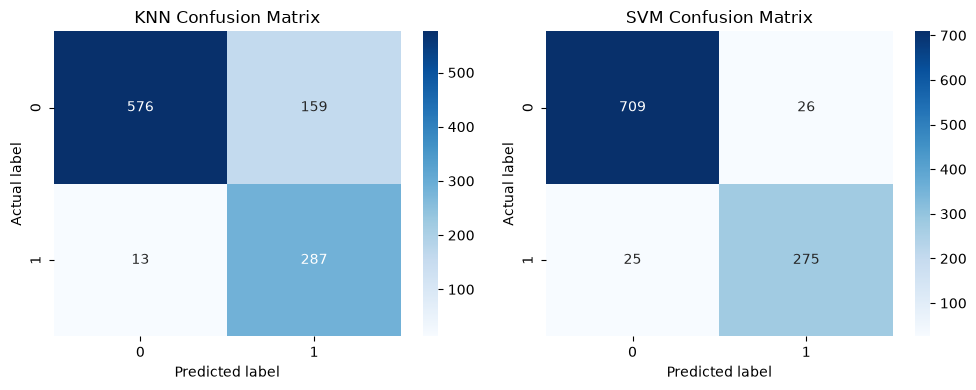

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name, predictions in [
    (axes[0], "KNN", knn_predictions),
    (axes[1], "SVM", svm_predictions)
]:
    sns.heatmap(
        confusion_matrix(y_test, predictions), annot=True, fmt="d",
        cmap="Blues", ax=ax
    )
    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()

## 11. Compare KNN and SVM

,Accuracy,Precision,Recall,F1 Score
Model,,,,
KNN,0.833816,0.643498,0.956667,0.769437
SVM,0.950725,0.913621,0.916667,0.915141


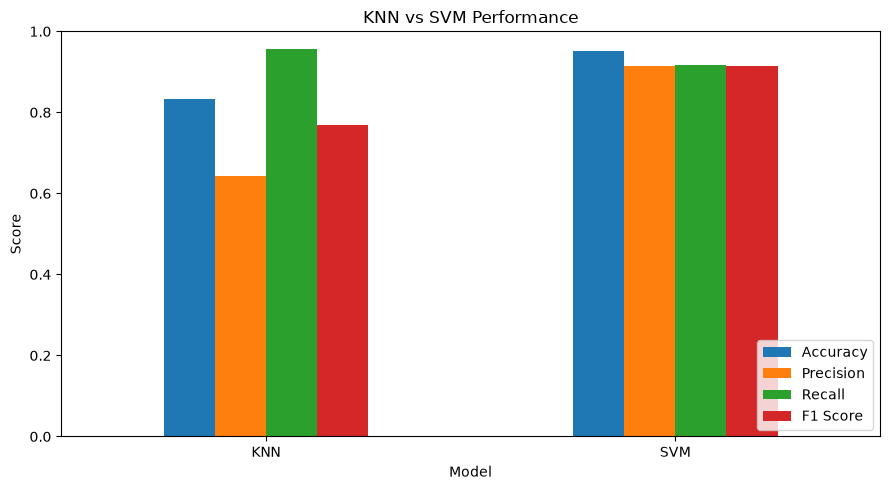

In [11]:
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [accuracy_score(y_test, knn_predictions), accuracy_score(y_test, svm_predictions)],
    "Precision": [precision_score(y_test, knn_predictions, zero_division=0), precision_score(y_test, svm_predictions, zero_division=0)],
    "Recall": [recall_score(y_test, knn_predictions, zero_division=0), recall_score(y_test, svm_predictions, zero_division=0)],
    "F1 Score": [f1_score(y_test, knn_predictions, zero_division=0), f1_score(y_test, svm_predictions, zero_division=0)]
})

display(results.set_index("Model"))

results.set_index("Model").plot(kind="bar", figsize=(9, 5))
plt.title("KNN vs SVM Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Conclusion

This notebook loads and cleans the email dataset, scales the word-count features, trains KNN and linear SVM classifiers, and compares them using accuracy, precision, recall, F1 score, classification reports, and confusion matrices.

**Note:** Results can vary with package versions and preprocessing. The `threadpoolctl` warning can occur in browser-based Pyodide environments; if the models finish training, it may be a non-fatal warning.